In [1]:
from ucimlrepo import fetch_ucirepo

In [2]:
bank_marketing = fetch_ucirepo(id=222)

In [3]:
x = bank_marketing.data.features
y = bank_marketing.data.targets
print(x.shape, y.shape)

(45211, 16) (45211, 1)


In [4]:
import pandas as pd

In [5]:
df = pd.concat([x,y], axis=1)

In [6]:
df.sample(10)

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
11718,45,blue-collar,single,primary,no,1006,no,no,NaN,20,jun,124,1,-1,0,NaN,no
19949,59,technician,divorced,tertiary,no,0,no,no,cellular,8,aug,124,4,-1,0,NaN,no
36592,33,entrepreneur,married,secondary,no,1034,yes,no,cellular,12,may,23,6,295,6,failure,no
32024,41,management,married,tertiary,no,-456,no,no,cellular,14,apr,427,4,144,1,failure,no
22946,53,blue-collar,married,primary,no,18,no,no,cellular,26,aug,55,4,-1,0,NaN,no
44651,48,NaN,single,NaN,no,1819,no,no,cellular,2,sep,1440,1,458,1,failure,yes
21470,31,housemaid,married,primary,no,979,no,yes,cellular,18,aug,298,10,-1,0,NaN,no
43732,74,retired,divorced,tertiary,no,3810,yes,no,cellular,17,may,492,1,-1,0,NaN,no
6919,27,admin.,single,secondary,no,242,yes,yes,NaN,28,may,83,1,-1,0,NaN,no
14244,34,management,married,tertiary,no,1906,yes,no,cellular,14,jul,68,3,-1,0,NaN,no


In [7]:
df.isnull().sum()

age                0
job              288
marital            0
education       1857
default            0
balance            0
housing            0
loan               0
contact        13020
day_of_week        0
month              0
duration           0
campaign           0
pdays              0
previous           0
poutcome       36959
y                  0
dtype: int64

In [8]:
df["job"] = df["job"].fillna("Unkown")

In [9]:
df["contact"] = df["contact"].fillna("Unknown")

In [10]:
df["poutcome"] = df["poutcome"].fillna("Unknown")

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.dtypes

age            int64
job              str
marital          str
education        str
default          str
balance        int64
housing          str
loan             str
contact          str
day_of_week    int64
month            str
duration       int64
campaign       int64
pdays          int64
previous       int64
poutcome         str
y                str
dtype: object

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          45211 non-null  int64
 1   job          45211 non-null  str  
 2   marital      45211 non-null  str  
 3   education    43354 non-null  str  
 4   default      45211 non-null  str  
 5   balance      45211 non-null  int64
 6   housing      45211 non-null  str  
 7   loan         45211 non-null  str  
 8   contact      45211 non-null  str  
 9   day_of_week  45211 non-null  int64
 10  month        45211 non-null  str  
 11  duration     45211 non-null  int64
 12  campaign     45211 non-null  int64
 13  pdays        45211 non-null  int64
 14  previous     45211 non-null  int64
 15  poutcome     45211 non-null  str  
 16  y            45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB


In [17]:
df.describe()

,age,balance,day_of_week,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

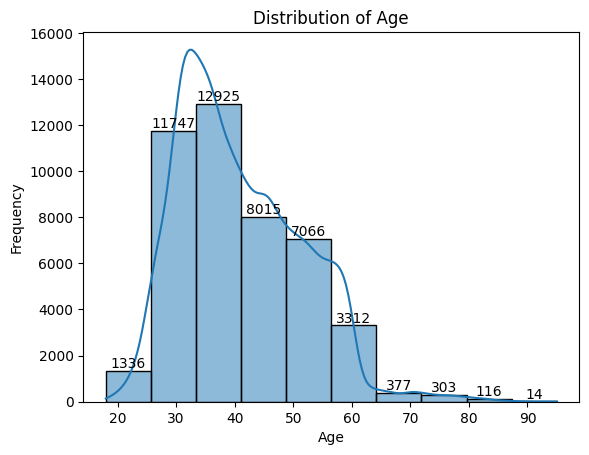

In [32]:
plt.Figure(figsize=(12, 6))

ax = sns.histplot(data=df, x='age', bins=10, kde=True)
for containers in ax.containers:
    ax.bar_label(containers)

plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

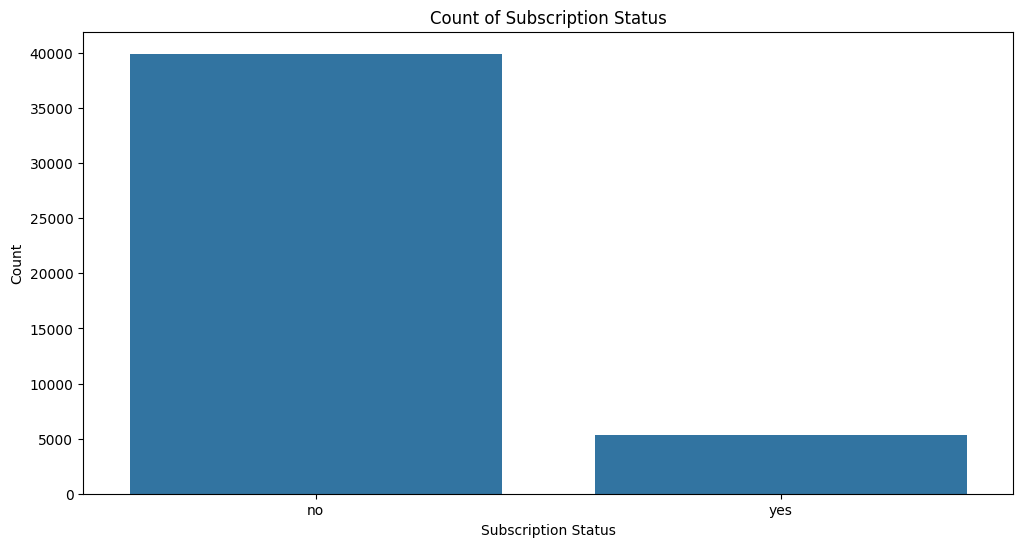

In [103]:
plt.figure(figsize=(12, 6))

sns.countplot(data=df, x='y')
plt.title('Count of Subscription Status')
plt.xlabel('Subscription Status')
plt.ylabel('Count')
plt.show()

In [111]:
df['age_group'] = pd.cut(df['age'], bins=range(10,101,10))

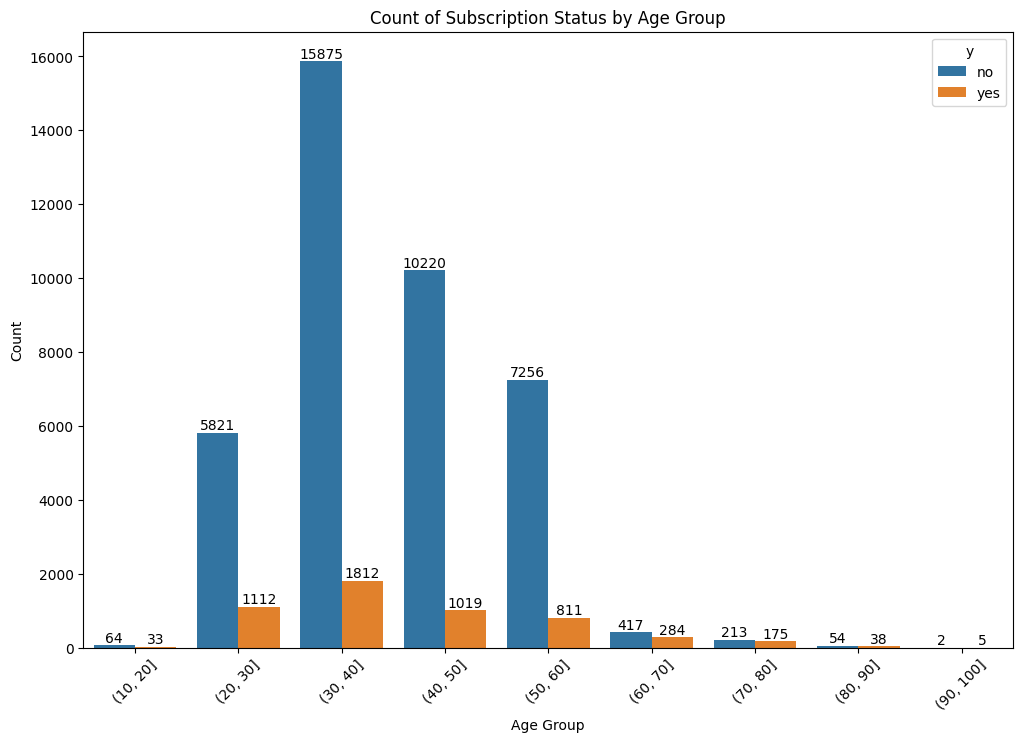

In [112]:
plt.figure(figsize=(12, 8))
ax = sns.countplot(data=df, x='age_group', hue='y')
for containers in ax.containers:
    ax.bar_label(containers)
plt.xticks(rotation=45)
plt.title('Count of Subscription Status by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Count')
plt.show()

In [113]:
pd.crosstab(df['age_group'], df['y'], normalize='index') * 100

y,no,yes
age_group,,
"(10, 20]",65.979381,34.020619
"(20, 30]",83.960767,16.039233
"(30, 40]",89.755187,10.244813
"(40, 50]",90.933357,9.066643
"(50, 60]",89.946696,10.053304
"(60, 70]",59.486448,40.513552
"(70, 80]",54.896907,45.103093
"(80, 90]",58.695652,41.304348
"(90, 100]",28.571429,71.428571


Text(0, 0.5, 'Count')

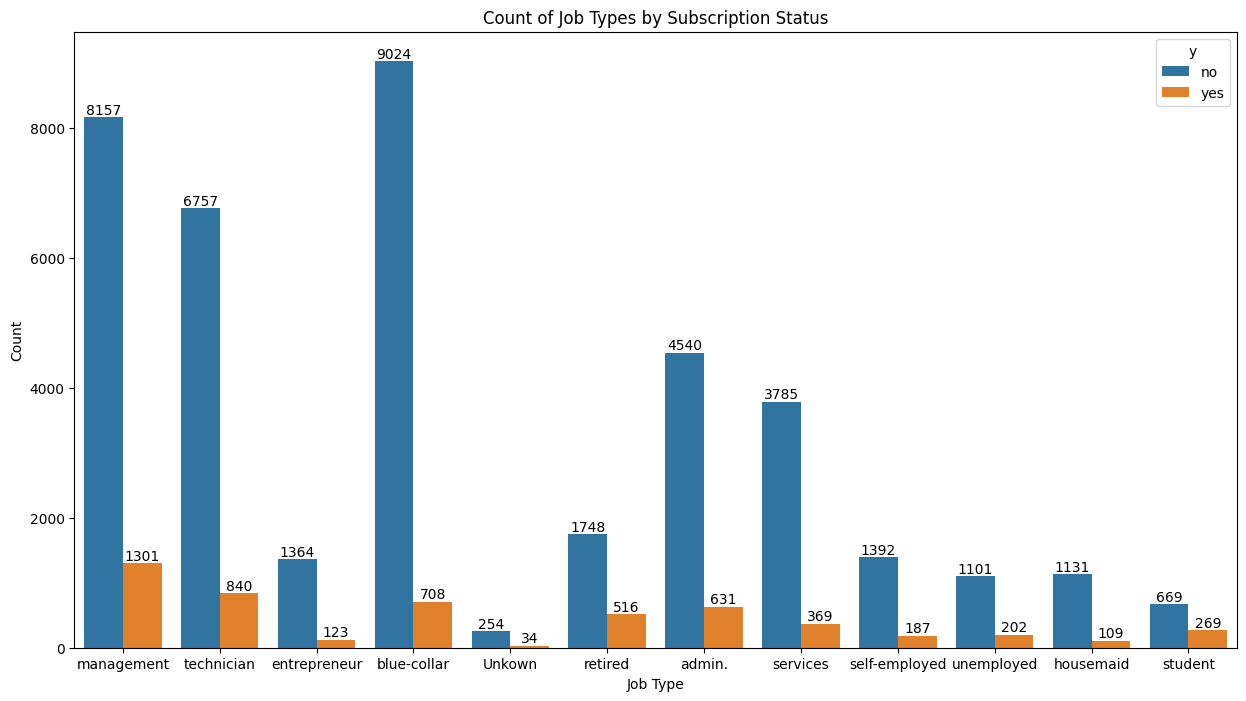

In [114]:
plt.figure(figsize=(15, 8))

ax = sns.countplot(data=df, x='job', hue='y')
for containers in ax.containers:
    ax.bar_label(containers)
plt.title('Count of Job Types by Subscription Status')
plt.xlabel('Job Type')
plt.ylabel('Count')

In [76]:
pd.crosstab(df['job'], df['y'],  normalize='index') * 100

y,no,yes
job,,
Unkown,88.194444,11.805556
admin.,87.797331,12.202669
blue-collar,92.725031,7.274969
entrepreneur,91.728312,8.271688
housemaid,91.209677,8.790323
management,86.244449,13.755551
retired,77.208481,22.791519
self-employed,88.157061,11.842939
services,91.116996,8.883004


In [115]:
pd.crosstab(df['marital'], df['y'], normalize='index') * 100

y,no,yes
marital,,
divorced,88.054542,11.945458
married,89.876534,10.123466
single,85.050821,14.949179


In [116]:
df['education'].value_counts()

education
secondary    23202
tertiary     13301
primary       6851
Name: count, dtype: int64

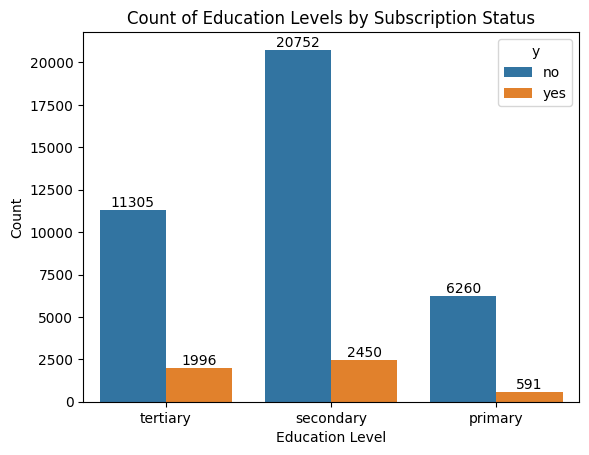

In [124]:
ax = sns.countplot(data=df, x='education', hue='y')
for containers in ax.containers:
    ax.bar_label(containers)
plt.title('Count of Education Levels by Subscription Status')
plt.xlabel('Education Level')
plt.ylabel('Count')
plt.show()

In [117]:
pd.crosstab(df['education'], df['y'], normalize = 'index') * 100

y,no,yes
education,,
primary,91.373522,8.626478
secondary,89.440565,10.559435
tertiary,84.993610,15.006390


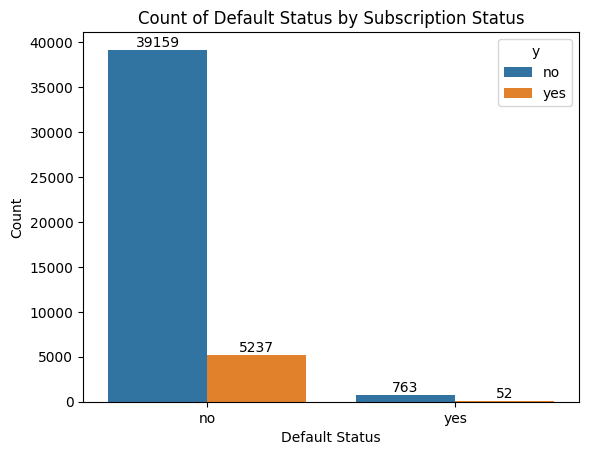

In [125]:
plt.Figure(figsize=(12, 6))

ax = sns.countplot(data=df, x='default', hue='y')
for containers in ax.containers:
    ax.bar_label(containers)
plt.title('Count of Default Status by Subscription Status')
plt.xlabel('Default Status')
plt.ylabel('Count')
plt.show()

In [121]:
pd.crosstab(df['default'], df['y'], normalize='index') * 100

y,no,yes
default,,
no,88.203892,11.796108
yes,93.619632,6.380368
